# Hunt an intruder in network logs with GFQL and semantic operators

A defended network logs 144,593 web requests in 21 minutes, and almost all of them are normal. A few are attacks, and a few attacks may have worked: the victim server opened a connection to a new host after its first outside request. This notebook uses a Cypher query over the connection log to keep only the requests that hit such a pivoting server, asks a model typed questions about them with `sem_decide`, and measures what each step saves in requests, cost and time.

![Five stages: time, cost and quality](gfql_semantic_zeek_hunt_chart.png)

*The chart comes from the run below. The numbers are simulated: the notebook answers with a calibrated mock model. See "What is real and what is simulated".*

| you will see | where |
|---|---|
| Cypher, `sem_decide`, a plan and a trace in one cell | **The pipeline in one cell** |
| what is real and what is simulated | **What is real and what is simulated** |
| the logs, the pivots, the rulebook and the simulator | **The data, the labels and the simulated model** |
| five stages with tables | **Stages 1 to 3**, **Stages 4 and 5** |
| the chart and a graph to plot | **The chart**, **The incident graph** |
| how to measure a live model (opt in, gated) | **Measure a live model** |

**Setup.** The first run downloads the public logs (about 50 MB) into `/tmp/zeek-wrccdc-cache`, so it needs network access. The helper module `zeek_hunt_helpers.py` holds the download, parse, rulebook, simulator, stage runners and chart code. The notebook expects it in the same folder (`demos/gfql/`): start Jupyter there, or add that folder to `sys.path`. The Appendix shows its source. Set `DEMO_LIVE=1` to use a live model (needs keys and spends money; see the end).

*Data: Zeek logs of the 2018-03-24 WRCCDC capture ([WRCCDC](https://www.wrccdc.org/)), from [`brimdata/zed-sample-data`](https://github.com/brimdata/zed-sample-data). The notebook downloads the logs from a pinned commit of the [`graphistry/zed-sample-data`](https://github.com/graphistry/zed-sample-data) fork of that repository. The data is licensed [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). This repository does not contain the data.*

In [1]:
import polars as pl

import zeek_hunt_helpers as h

h.init()    # download (once), find pivots, label each request, build the graph

from graphistry import e_forward, n
from graphistry.compute.semantic import (
    MemorySemanticCache,
    bind_providers,
    explain_sem_decide,
    semantic_summary,
    semantic_trace,
    semantic_verdicts,
)
from zeek_hunt_helpers import (
    EVIDENCE,
    OPTIONS,
    PARALLEL,
    QUESTIONS,
    decisions_provider,
    g,
    session_for,
    show,
)

print("mode:", "LIVE model (opt in)" if h.DEMO_LIVE else "simulated model ($0, no key)")

WRCCDC Zeek logs (full download) | 144,593 web requests | 3,380 connection pairs from defended hosts | read in 5 s


144,593 web requests | 83 victims | 38 pivoting victims | 563 nodes | 145,153 edges
mode: simulated model ($0, no key)


## The pipeline in one cell

**Input:** a Cypher query keeps the web requests that hit a defended server that later opened a connection to a new host (a *pivot*, one to three hops). The `RETURN` carries the request text that the model reads, because the `http` edges hold it, so `.sem_decide` runs on the query result with no glue. **Config:** three typed questions, a provider and a probability limit (`min_p`). **Output:** one verdict for each request, a plan before the run and a trace after it. The provider is simulated here, so the cell costs $0.

In Cypher, `[s:http]` and `[:conn*1..3 ...]` read the `type` column of the edges. A variable-length pattern followed by more hops runs on the pandas engine (the default `engine="auto"`); the GFQL chain below runs natively on Polars. This cell leaves `dedupe` on, its default: a repeated request text is asked once. The stages below pass `dedupe=False`, so that each stage asks about every row, as a plain loop does.

In [2]:
# 1. Input: narrow the graph with Cypher
candidates = g.gfql("""
    MATCH (o {zone: 'outside'})-[s:http]->(v {zone: 'blue'})
          -[:conn*1..3 {is_pivot: true}]->(t)
    RETURN DISTINCT s.uid AS uid,
                    s.method AS method,
                    s.host AS host,
                    s.uri AS uri,
                    s.user_agent AS user_agent,
                    s.status AS status
""")

# 2. Config: typed questions (QUESTIONS), a provider and guardrails
provider = decisions_provider(session_for())  # simulated unless DEMO_LIVE=1
args = dict(
    questions=QUESTIONS,
    task_id="web-request-triage",
    evidence_cols=EVIDENCE,
    id_col="uid",
    max_concurrency=PARALLEL,
    require_probabilities=True,
    min_p=0.85,
    **OPTIONS,  # live mode adds budget={"max_cost_usd": 0.50}
)

# 3. Run: a plan (no request), then the decisions on the Cypher result, under a trace
plan = explain_sem_decide(candidates._nodes, provider=provider, **args)
cache = MemorySemanticCache()
with bind_providers({"triage": provider}, cache=cache), semantic_trace() as runs:
    triaged = candidates.sem_decide(provider="triage", **args)

# 4. Output: status counts that never hide an unanswered row, the verdicts, and the trace
verdict = semantic_verdicts(triaged._nodes, "triage_priority", positive="contain_now")
show(semantic_summary(triaged._nodes))
show(verdict.value_counts().rename("requests").to_frame().T)
print(
    f"plan: {plan['planned_calls']:,} calls for {plan['active_rows']:,} requests, "
    f"dedupe saves {plan['dedupe_saved_rows']:,} | "
    f"run: {runs[0]['provider_calls']:,} calls, billed ${runs[0]['billed_cost_usd']:.2f}"
)

*SIMULATED model on real WRCCDC Zeek logs*

,ok,uncertain,error,skipped,unanswered,unanswered_pct
question,,,,,,
is_exploitation,18125,2269,0,0,2269,11.13
attack_stage,18017,2377,0,0,2377,11.66
triage_priority,18175,2219,0,0,2219,10.88


*SIMULATED model on real WRCCDC Zeek logs*

,no,uncertain,yes,error,skipped
requests,17421,2219,754,0,0


plan: 7,682 calls for 20,394 requests, dedupe saves 12,712 | run: 7,682 calls, billed $6.70


In [3]:
# The same query as a GFQL chain (Python objects), on the Polars engine
pivot_chain = [
    n({"zone": "outside"}),
    e_forward({"type": "http"}, name="session"),
    n({"zone": "blue"}, name="victim"),
    e_forward({"type": "conn", "is_pivot": True}, min_hops=1, max_hops=3),
    n(),
]
chain_ids = g.gfql(pivot_chain, engine="polars")._edges.filter(pl.col("session"))["uid"]
hero_ids = set(candidates._nodes["uid"])
assert set(chain_ids) == hero_ids, "Cypher and the chain must agree"
print(f"{len(chain_ids):,} requests from the chain: the same rows as the Cypher query")

20,394 requests from the chain: the same rows as the Cypher query


`contain_now` with a probability of at least 0.85 is a `yes`. `uncertain` goes to an analyst queue. An `error` or `skipped` row is never counted as `no`. The rest of the notebook builds this cell up in five stages and measures each one.

## What is real and what is simulated

The web requests, the connections and the GFQL queries are **real**. The default run sends **no request to a model**, uses **no API key** and costs **$0**. A *simulated* model answers the questions. Its cost, time and accuracy come from stated assumptions, not from a live benchmark. Every result table and chart says "simulated". Set `DEMO_LIVE=1` to measure a live model (see the end of the notebook).

**The labels are rule-based.** The logs hold no list of attacks. The only notices in `notice.log` are SSL certificate warnings, so they cannot label attacks (the data tables count them). The notebook scores every answer against a small fixed rulebook (like an intrusion detection ruleset) and against evidence in the connection log. Nobody checked these labels by hand. The prompts never contain a label.

## The data, the labels and the simulated model

**Logs.** Zeek writes one line of JSON for each event. The notebook uses two logs:

- `http.log`: one line for each web request (method, host, path, user agent, status). The notebook names a request `uid.trans_depth`, because one connection can carry many requests.
- `conn.log`: one line for each connection between two hosts (about one million lines).

The helper module reads the logs in `/tmp/zeek-wrccdc-cache`, or downloads them from a pinned commit of the `graphistry/zed-sample-data` fork (a download goes to a temporary name first, so a stopped download never leaves a broken file). The notebook commits no dataset file. The defended network is `10.47.0.0/16` (its web servers sit at `10.47.x.58` and similar). Every other address is **outside**. The notebook keeps one row for each connection pair, not for each connection: only the first time that a server contacts a host matters here.

**Victims and pivots.** A **victim** is a defended host that received a web request from outside. A **pivot** is a connection that a victim opens to a host that it had **not contacted on any port before its first outside request**, on a port that is not routine infrastructure (DNS, NTP, ident, NetBIOS names, syslog, DHCP). Zeek times both events, so the order is known. This is a heuristic and not proof of a break-in: most pivot connections here go to ports 80 and 443, which can be ordinary outbound web use. A **pivoting victim** has at least one pivot. The test is per server: it does not check that a given request came before the pivot, and many requests arrive after the first pivot.

**The graph.** Nodes are hosts, with a `zone` of `outside` or `blue` (the defended network). Edges are `http` (one for each web request, from the client to the server, carrying the request text) and `conn` (one for each connection pair that a defended host opened, with an `is_pivot` flag).

**Three questions.** The model reads one web request at a time: the method, the host header, the path, the user agent and the status. The Host header often holds the server address, so the model can see the destination. It does **not** see the source address, the zone or any label. It answers three typed questions:

| question | kind | answers |
|---|---|---|
| `is_exploitation` | `predicate` | is this request an attempt to run code or read files on the server? |
| `attack_stage` | `choice` | `webshell_or_rce`, `sqli_or_lfi`, `recon_scan` or `benign` |
| `triage_priority` | `score` | `ignore`, `investigate` or `contain_now` |

The held-out answers come from a small rulebook over the same text (a stand-in for an intrusion detection ruleset). **A rulebook is not a human analyst.** A live model gets scored on how well it agrees with these rules.

- `webshell_or_rce`: a shell function in a header or path, a command in a parameter, a shell path, or a known remote-code pattern
- `sqli_or_lfi`: `../`, `/etc/passwd`, `win.ini`, `union select`, or a script tag
- `recon_scan`: a known scanner user agent (WPScan, Nmap, Nessus and similar), or a probing method such as `PROPFIND`
- `benign`: the rest

`is_exploitation` is true for the first two. `triage_priority` is `contain_now` for them, `investigate` for `recon_scan` and `ignore` for the rest. An exploit attempt only needs containment when the server is a pivoting server, and one request cannot show that. The **positive class** is therefore an exploit attempt from outside **on a pivoting victim**. It uses the same pivot evidence as the GFQL query, so GFQL keeps every positive **by design**: a test of its recall would prove nothing. The measured part is how many rows each filter keeps and which rows it drops. The positives also sit on few servers (stage 3 prints how many).

**Simulated model.** The default run does **not read** the request text. It looks up the held-out label of the request and corrupts it, and it replays one fixed random draw for each distinct request text and question, so every stage sees the same answers.

- The model is **calibrated by construction**: it holds a confidence `p` for each answer and is right with probability `p`. When it is wrong, it picks another answer at random.
- Normal traffic is **easier** than attacks. Confidence is drawn from `Beta(24, 1.5)` (mean 0.94) for `benign` requests and from `Beta(10, 2)` (mean 0.83) for the others. Without this, the naive scan would look worse than a real model would on the flood of normal requests.
- Because `p` does not depend on the text, any gain from `min_p` below is a property of this simulator. A real model can be less calibrated, and you must measure it.
- Token counts come from the real request text (four characters per token). Prices and latency are assumptions. **None of these numbers is measured.** They show how the stages combine. They do not rank a real model.

In [4]:
h.data_summary()

,uid,src,dst,dport,method,host,uri,user_agent,status,ts_ms,inbound,attack_stage,is_exploitation,triage_priority,on_pivot_victim,positive
0,CWocsz4DZqCwMcqpI2.1,10.164.94.120,10.47.3.200,80,GET,10.47.3.200,/chassis/config/GeneralChassisConfig.html,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 5.1; Trident/4.0),301,1521911720609,True,benign,False,ignore,True,False
1,CcusWv1scSClJIjVY.1,10.164.94.120,10.47.3.200,80,GET,10.47.3.200,/Webcam/webcam.html,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 5.1; Trident/4.0),301,1521911720611,True,benign,False,ignore,True,False
2,CYsPKt2rH2nY777FMe.1,10.164.94.120,10.47.27.80,8080,GET,10.47.27.80:8080,/test.cgi,() { _; } >_[$($())] { echo Content-Type: text/plain ; echo ; echo...,404,1521911720612,True,webshell_or_rce,True,contain_now,True,True


83 victims | 38 pivoting victims | 198 pivot connections


,new hosts reached
src,
10.47.1.208,27
10.47.3.151,24
10.47.3.155,23
10.47.8.151,13
10.47.26.160,12


563 nodes | 145,153 edges


,nodes,edges
blue,139.0,NaN
outside,424.0,NaN
conn,NaN,560.0
http,NaN,144593.0


144,593 web requests | 139,009 come from outside | 20,394 hit a pivoting victim | 1,171 are exploit attempts on a pivoting victim
columns that the model reads: ['method', 'host', 'uri', 'user_agent', 'status'] (no source address, no zone, no label; the Host header can hold the server address)


,requests,on_pivot_victim
attack_stage,,
webshell_or_rce,928,524
sqli_or_lfi,936,647
recon_scan,9368,9323
benign,127777,9900


notice.log: 207 notices | types: {'SSL::Invalid_Server_Cert': 207}


,assumption,value
0,model confidence p (mean),"normal traffic 0.94, attacks 0.83"
1,chat latency for one request,0.9 s
2,decisions latency for one request,1.2 s + 0.15 s for each question
3,"parallel requests, stages 1 to 3",1 (one request at a time)
4,"parallel requests, stages 4 and 5",8
5,price per million tokens (input / output),$2.5 / $10.0


## Stages 1 to 3: ask about everything, filter flat, or follow the graph

Each stage asks the same three questions with the chat provider, one request at a time, with `dedupe=False`, as a plain loop over a chat API does. The tables show `rows` (all rows of the stage) and `asked` (rows that the model answered). In the default run they are equal.

1. **Naive scan.** Every web request. The model reads one request and cannot know whether the server is a pivoting server, so a table splits what it flags as `contain_now`.
2. **Flat filter (no graph).** An analyst with only `http.log` keeps the requests from outside that have a method other than `GET` or `HEAD`, or a status of 400 or more, or a path with an odd character (`..`, `%`, `;`, `|`, `<`, quotes, `cgi`, `cmd`, `exec`, `passwd`), or a user agent with a brace or a scanner name. It does not use the connection log.
3. **GFQL pivot filter.** The graph query of the hero cell. The `is_pivot` flag is a column that the notebook computed from the order of two events, and the query matches the path. It runs without a model call. **What to expect:** the two filters keep about the same number of rows in the full run, so the model reads as many requests in stage 3 as in stage 2, and cost and time stay the same. GFQL changes **which** requests the model reads, and ties them to the connection log. Precision rises mostly because the exploit attempts on servers that never pivoted no longer count as false flags. The model does not get better.

In [5]:
h.stage1()
h.stage2()

rows asked: 144,593 of 144,593 | local run time 94.6 s


*SIMULATED model on real WRCCDC Zeek logs*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,144593,144593,433779,185.169,390401.1,4660,962,0,0.206,0.822,0


*SIMULATED model on real WRCCDC Zeek logs*

,requests flagged by the naive scan
right: an exploit attempt on a pivoting victim,962
"an exploit attempt, but the server never pivoted",572
model mistake: not an exploit attempt,3126


144,593 requests -> 20,452 after the flat filter (7x fewer rows)


*SIMULATED model on real WRCCDC Zeek logs*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,20452,20452,61356,24.537,55220.4,1914,955,0,0.499,0.821,0


In [6]:
h.stage3()

,step,requests left,removed by,positives kept
0,all web requests,144593,,1171
1,flat filter,20452,plain table filter,1163
2,GFQL pivot filter,20394,"GFQL on polars, 60 ms (median of 5)",1171


GFQL: 144,593 -> 20,394 requests in 60 ms | the flat filter keeps 20,452
The 1,171 positives sit on 14 servers; the busiest one holds 458. Positives are counted by construction from the same pivot evidence, so GFQL keeps all of them.
The flat filter keeps 20,452 rows and GFQL keeps 20,394. The flat filter also keeps 686 exploit attempts on servers that never pivoted. GFQL keeps 4,362 requests that the flat filter drops, on servers that did pivot.


*SIMULATED model on real WRCCDC Zeek logs*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,20394,20394,61182,24.588,55063.86,1345,962,0,0.715,0.822,0


## Stages 4 and 5: one call for three questions, then calibrated answers

4. **Three questions in one call, eight calls at once.** `OpenAIDecisionsProvider` asks all three questions about a request in one call and shares the request text. The second table compares ways to send the same rows: concurrency, the shared call, and packing 8 rows per call (`rows_per_request=8`). Packing cuts calls and latency. It does not cut tokens, and it gives up the sharing across questions.
5. **`min_p` and `sem_map`.** `require_probabilities=True` accepts an answer only when the provider measured its probability, and `min_p=0.85` turns a lower one into `uncertain`, which goes to the analyst queue instead of a guess. `sem_map` then writes one finding for each request that is `contain_now` or `uncertain`. Its evidence holds the victim address and the number of new hosts that the victim reached, which come from the GFQL result, not from the request text. The findings run 8 at a time and are capped by request count, because a `sem_map` call has no cost estimate here. It passes `dedupe=False`, like stages 1 to 4, so each row gets its own request.

**What to read in the next cells.** The accuracy table scores each question against the held-out answer. In the simulated run `min_p` raises the accuracy of the accepted answers by construction, because the simulated confidence is calibrated. The `min_p` replay reads any threshold off the probabilities of stage 4. In this simulator `min_p` does not raise precision much: most wrong flags come from normal requests, which the simulator answers with high confidence, so the threshold does not catch them. A live model can behave differently, and the live mode measures it.

In [7]:
h.stage4()
h.stage5()

probability kinds: {'native_decision': 20394}


*SIMULATED model on real WRCCDC Zeek logs*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,20394,20394,20394,17.545,4206.322,1345,962,0,0.715,0.822,0


*SIMULATED model on real WRCCDC Zeek logs*

,how the same rows are sent,requests,cost_usd,seconds
0,"chat, 1 question per call, 1 at a time (stage 3)",61182,24.588,55063.800
1,"chat, 1 question per call, 8 at once",61182,24.588,6882.975
2,"3 questions per call, 8 at once (stage 4)",20394,17.545,4206.263
3,"8 rows packed per call, 8 at once",2550,22.124,1529.662


contain_now: 754 | analyst queue: 2219 | findings: {'ok': 2973} | sem_map cost $2.1606


*SIMULATED model on real WRCCDC Zeek logs*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors,uncertain_pct
0,20394,20394,23367,19.706,4540.785,754,530,592,0.703,0.453,0,10.881


In [8]:
h.diagnostics()

*SIMULATED model on real WRCCDC Zeek logs*

,question,kind,stage 4 accuracy,stage 4 answered,stage 5 accuracy,stage 5 answered
0,is_exploitation,predicate,0.944,20394,0.972,18125
1,attack_stage,choice,0.949,20394,0.972,18017
2,triage_priority,score,0.951,20394,0.974,18175


*SIMULATED model on real WRCCDC Zeek logs*

,min_p,contain_now,precision,recall,analyst queue
0,0.50,1335,0.718,0.819,0%
1,0.70,1219,0.725,0.755,2%
2,0.80,979,0.724,0.605,7%
3,0.85,754,0.703,0.453,11%
4,0.90,452,0.704,0.272,54%
5,0.95,157,0.707,0.095,73%


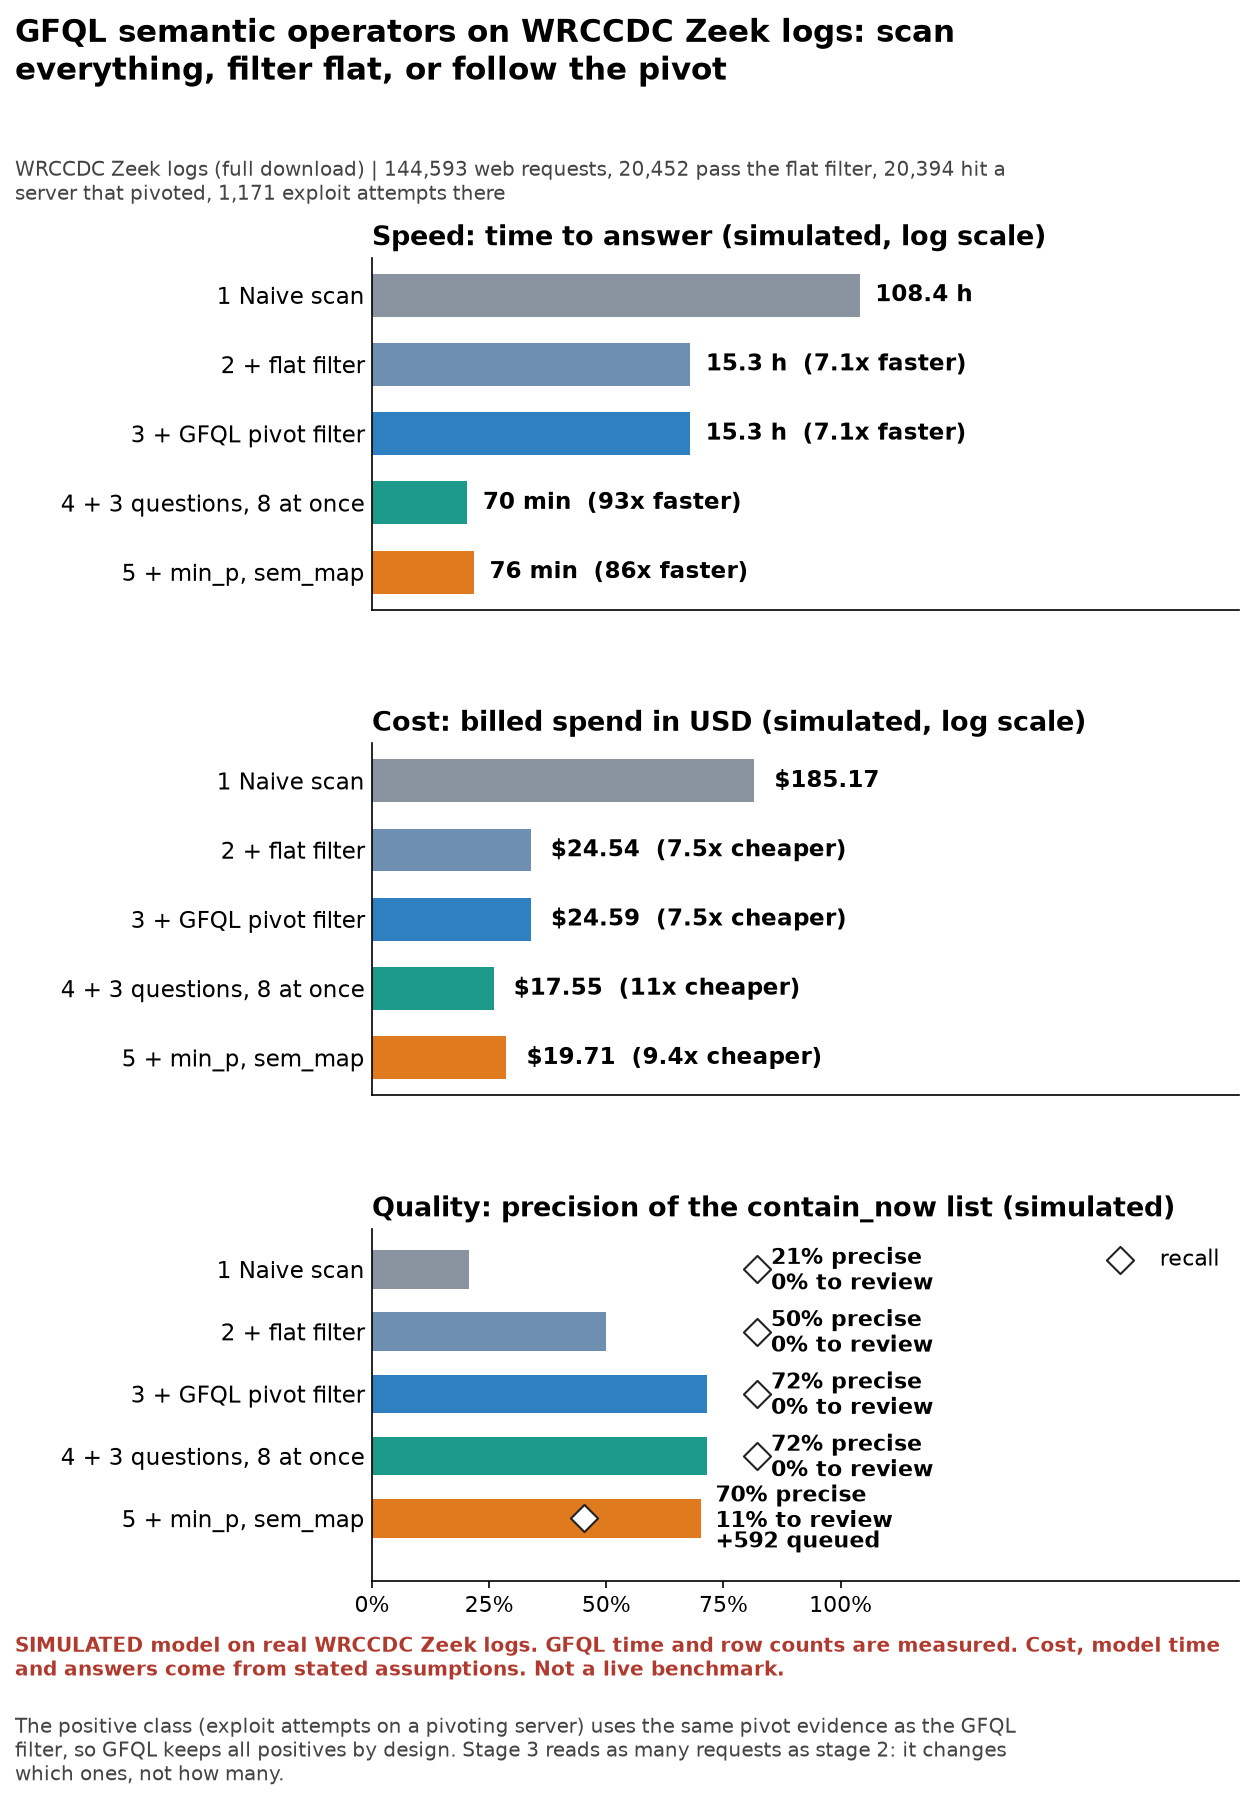

saved gfql_semantic_zeek_hunt_chart.png


In [9]:
h.chart()

## The chart

The chart above shows time, model spend and the precision of the `contain_now` list for the five stages. The time and cost axes are logarithmic. Stage 1 is a deliberately plain baseline: one call at a time, no filter. The simulator sets the latency of a call, so the time gains are modeled and not measured. The step that GFQL adds is stage 3, and it changes which requests the model reads, not how many.

## The incident graph

A second GFQL query follows the path of the requests that need action. It starts at the outside hosts that sent one of the requests marked `contain_now` or `uncertain`, goes to the victim and then follows the pivot connections to the hosts that the victim reached.

In [10]:
h.incident()

incident query: 48 ms | 136 nodes, 3122 edges
preview only: set DEMO_PLOT=1 after graphistry.register(...) to open the graph


,hosts
role,
attacker,16
reached by a victim,98
victim,22


*SIMULATED model on real WRCCDC Zeek logs*

,uid,victim,new_hosts,verdict,triage_priority__p,finding
0,CPjnSQ8GXTWnLnB4d.1,10.47.1.208,27,flagged,0.984,GET /mJT49g66.ashx to 10.47.1.208 (status 403); the server reached...
1,CAjQg04DBWslkdyozi.1,10.47.3.151,24,uncertain,0.683,GET /note.txt?F_notini=&T_note=&nomentreprise=blah&filenote=../../...
2,Czpo1z3h4pszeEOR7e.1,10.47.3.155,23,flagged,0.857,GET /note.txt?F_notini=&T_note=&nomentreprise=blah&filenote=../../...
3,C20VSf4YNj6FqWjAEk.1,10.47.8.151,13,flagged,0.993,GET /cgi/mid.cgi to 10.47.8.151 (status 0); the server reached 13 ...
4,CadAVf15NgwqRpmwUa.1,10.47.26.160,12,flagged,0.866,GET /note.txt?F_notini=&T_note=&nomentreprise=blah&filenote=../../...
5,CTMm8R1UWBSXtMyhQe.2,10.47.22.186,8,uncertain,0.838,GET /wordpress/wp-content/plugins/random-image-gallery-with-pretty...
6,Cvheod4zDMPUphCAZ8.90,10.47.26.186,5,flagged,0.955,GET /wordpress/wp-admin/js/user-profile.min.js to 10.47.26.186 (st...
7,CK8f5dzRRJm8kEfl7.1,10.47.23.80,5,uncertain,0.783,GET / to 10.47.23.80 (status 200); the server reached 5 new hosts ...


*SIMULATED model on real WRCCDC Zeek logs*

,victim,method,uri,status,triage_priority__p
5852,10.47.3.142,GET,/cgi-bin/..\xc0%9v..\xc0%9v..\xc0%9v..\xc0%9v..\xc0%9v../winnt/sys...,400,0.85
8938,10.47.26.186,GET,/wordpress/wp-content/plugins/subscribe-to-comments-reloaded/,404,0.85
19980,10.47.26.186,GET,/wordpress/wp-includes/js/tinymce/plugins/media/editor_plugin.js,404,0.85
8611,10.47.26.186,GET,/wordpress/wp-includes/js/tinymce/plugins/media/editor_plugin.js,404,0.85
12947,10.47.26.186,GET,/wordpress/wp-includes/js/tinymce/plugins/media/editor_plugin.js,404,0.85


In [11]:
h.summary()

SIMULATED model on real WRCCDC Zeek logs | WRCCDC Zeek logs (full download)
Rows: 144,593 web requests -> 20,452 after the flat filter -> 20,394 after the GFQL pivot filter (60 ms).
GFQL keeps the requests on servers that pivoted, and all 1,171 exploit attempts on them. That recall is by design: the positive class uses the same pivot evidence. The flat filter keeps 1,163 of them.
GFQL does not cut cost or time against the flat filter ($24.54 and 15.3 h against $24.59 and 15.3 h). It changes which requests the model reads. Stages 4 and 5 cut cost and time. Stage 5 adds findings and a queue, so it costs a little more than stage 4.
Precision of the contain_now list: naive 21%, flat 50%, GFQL 72%, with min_p 70%. Recall with min_p: 45% flagged, and 592 more positives wait in the analyst queue (11% of the requests).
Requests: 433,779 -> 61,356 -> 61,182 -> 20,394 (3 questions per call) -> 23,367 with 2,973 findings (stage 5 rows asked: 20,394).
Cost: $185.17 -> $24.54 -> $24.59 -> $17.55 ->

## Measure a live model (opt in)

Set `DEMO_LIVE=1` and restart the notebook. The same code then runs with real providers. The run sends web request text to
the model provider and the provider bills you. These limits stay on:

- the decision stages use `budget={"max_cost_usd": 0.50}`. The cap bounds the **estimated input cost** of a stage. It does not bound output, retries or the real bill, so check your provider's usage page
- stages 1 to 3 ask about a random sample of 50 requests each, and stages 4 and 5 about 200. The notebook scales their cost and time to all rows. It does not report the quality of stage 1, because 50 random requests hold almost no positive. The quality of the other stages comes from small samples, so read it as rough
- the `sem_map` findings have no cost estimate. They are capped by request count: one request for each request that needs action
- the chart footer says "Measured with a live model"
- the chat provider and the decisions provider both use `OPENAI_BASE_URL`

Set these variables first. Do not put a key in a notebook.

| variable | meaning |
|---|---|
| `OPENAI_API_KEY` | key for an OpenAI-compatible host |
| `OPENAI_BASE_URL` | optional host URL. Default `https://api.openai.com/v1` |
| `OPENAI_CHAT_MODEL` | model for stages 1 to 3 and for the `sem_map` findings |
| `OPENAI_DECISIONS_MODEL` | model for the decisions endpoint in stages 4 and 5 |
| `PRICE_IN`, `PRICE_CACHED`, `PRICE_OUT` | your prices in USD for one million tokens |

Check your data policy first. These logs are public. Real network logs hold private addresses, paths and user names, and
you must not send them to a provider that your policy does not allow. The same code works on your own logs.

## Appendix: the helper module

`zeek_hunt_helpers.py` sits next to this notebook. It holds the Zeek log download and parse, the pivot analysis, the rulebook, the simulated model (a mock HTTP session that answers in the OpenAI format), the stage runners and the chart. The cell below shows its source.

In [12]:
from IPython.display import Code

Code(filename="zeek_hunt_helpers.py", language="python")

# flake8: noqa: F821
"""Helpers for the Zeek threat-hunt demo (gfql_semantic_zeek_hunt.ipynb).

The notebook shows the GFQL and semantic-operator calls. This file holds the plumbing: the Zeek log download and parse, the pivot analysis, the
rulebook that labels each request, the simulated model (a calibrated mock HTTP session), the stage runner and the chart.
Call `init()` once, then `from zeek_hunt_helpers import *`.
"""


import gzip
import hashlib
import json
import math
import os
import re
import textwrap
import threading
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import graphistry
from graphistry import e_forward, n
from graphistry.compute.predicates.is_in import is_in
from graphistry.compute.semantic import (CallableGenerationProvider, OpenAIChatProvider, OpenAIDecisionsProvider, ProviderCapabilities, TokenPrices,
                                         sem_decide, sem_map)
from IPython.display import Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)


DEMO_LIVE = os.environ.get("DEMO_LIVE") == "1"
ZEEK_URL = "https://raw.githubusercontent.com/graphistry/zed-sample-data/8da0758e1ee1a8f94895d640a7646fd2c27ca803/zeek-json"
CACHE_DIR = Path("/tmp/zeek-wrccdc-cache")
URI_CHARS = 200                                       # the model reads the first 200 characters of a path


def cached(name):
    """Path of a downloaded log. A download goes to a temporary name first."""
    path = CACHE_DIR / f"{name}.json.gz"
    if not path.exists():
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        part = path.with_suffix(".part")
        with urllib.request.urlopen(f"{ZEEK_URL}/{name}.json.gz", timeout=120) as reply:
            part.write_bytes(reply.read())
        part.replace(path)
    return path


def lines(path, contains=None):
    """JSON records of a Zeek log. `contains` skips the lines without that text before parsing."""
    with gzip.open(path, "rt", encoding="utf-8") as handle:
        for line in handle:
            if contains is None or contains in line:
                yield json.loads(line)


def millis(ts):
    return ((pd.to_datetime(ts, utc=True) - pd.Timestamp("1970-01-01", tz="UTC")) // pd.Timedelta(milliseconds=1)).astype("int64")


def read_http(path):
    rows = [(f"{d['uid']}.{d.get('trans_depth', 1)}", d["ts"], d["id.orig_h"], d["id.resp_h"], d["id.resp_p"], d.get("method") or "", d.get("host") or "", (d.get("uri") or "")[:URI_CHARS],
             d.get("user_agent") or "", int(d.get("status_code") or 0)) for d in lines(path)]
    frame = pd.DataFrame(rows, columns=["uid", "ts", "src", "dst", "dport", "method", "host", "uri", "user_agent", "status"])
    frame["ts_ms"] = millis(frame.pop("ts"))
    return frame


def read_conn_edges(path):
    """One row for each (source, destination, port) of a connection that a defended host opened, with the time of the first one."""
    rows = [(d["ts"], d["id.orig_h"], d["id.resp_h"], d["id.resp_p"]) for d in lines(path, contains='"id.orig_h":"10.47.')]
    frame = pd.DataFrame(rows, columns=["ts", "src", "dst", "dport"])
    frame["ts_ms"] = millis(frame.pop("ts"))
    return frame.groupby(["src", "dst", "dport"], as_index=False).agg(first_ms=("ts_ms", "min"), connections=("ts_ms", "size"))


def load_zeek():
    """Return (http sessions, connection pairs of defended hosts, source label). Downloads the logs into CACHE_DIR when they are not cached."""
    try:
        return read_http(cached("http")), read_conn_edges(cached("conn")), "WRCCDC Zeek logs (full download)"
    except (OSError, EOFError, ValueError) as error:
        if isinstance(error, (gzip.BadGzipFile, EOFError)):
            for name in ("http", "conn"):
                (CACHE_DIR / f"{name}.json.gz").unlink(missing_ok=True)       # drop a broken cache so the next run downloads again
        raise RuntimeError(f"